# Grokking on Modular Addition: Fourier Circuit Analysis in a 1-Layer Transformer

## Summary
A one-layer transformer is trained on $(a + b) \bmod 113$ using only **30% of all pairs** and strong weight decay. This setup reproduces *grokking* (Power et al., 2022): training accuracy reaches 100% by epoch 200, but test accuracy stays low (0.026 at epoch 200, 0.038 at epoch 1000) and first exceeds 90% only at **epoch 10,000**.


| Question | What this notebook shows |
|---|---|
| Is the embedding sparse in the Fourier basis? | Yes, 5 key frequencies: **k ∈ {5, 9, 17, 28, 43}** |
| Does the unembedding use the same frequencies? | Yes, identical set (overlap 5/5) |
| Are these frequencies *causally* needed? | Keeping only them: test acc **1.000**. Removing them: test acc **0.003** |
| Is it the *embedding* alone that matters? | Projecting the embedding onto key freqs: **0.997**; onto the other freqs: **0.016** |
| Does Fourier structure appear only after memorisation? | Key-frequency energy fraction in the embedding: **0.141** (memorising checkpoint) → **0.851** (grokked) |

## Contents
1. Setup · 2. Task & dataset · 3. Model · 4. Training setup · 5. Training · 6. Training dynamics · 7. Fourier analysis of embeddings · 8. Neurons & attention · 9. Unembedding · 10–11. Causal tests (ablations) · 12. Memorising vs. grokked solution · 13. Progress measure · 14. Summary, limitations, references

## 1. Setup & reproducibility
Fixed seed (`SEED = 0`) for Python, NumPy and PyTorch. The model is small (~227k parameters), and the full run (12,000 full-batch epochs) is feasible on CPU.

In [1]:
import sys
import torch
import transformer_lens
import einops
import numpy as np
import matplotlib.pyplot as plt

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Grokking environment ready!")

Python: C:\Users\jenil\.conda\envs\PROJECT\python.exe
PyTorch: 2.14.0+cpu
CUDA available: False
Grokking environment ready!


In [2]:
import random

# Reproducibility: same random sequence
SEED = 0

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Select CPU or GPU automatically
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Random seed:", SEED)
print("Using device:", device)

Random seed: 0
Using device: cpu


## 2. Task and dataset
**Task:** given two integers $a, b \in \{0,\dots,112\}$, predict $(a+b) \bmod p$ with $p = 113$.

**Input format:** a 3-token sequence `[a, b, =]`. The vocabulary has $p + 1 = 114$ tokens (113 numbers plus a special `=` token with id $p$). The prediction is read from the logits at the **final (`=`) position**.

**Split:** all $p^2 = 12{,}769$ pairs are shuffled, then 30% are used for training (3,830) and 70% for testing (8,939). The small training fraction is what makes memorisation easy and generalisation delayed.

The cells below build the dataset and *assert* its correctness (sizes, ranges and every label).

In [3]:
# Modulus
p = 113

# Vocabulary size:
# 113 number tokens + 1 special "=" token
vocab_size = p + 1

# Sequence length: a, b, =
seq_len = 3

print("Modulus:", p)
print("Vocabulary size:", vocab_size)
print("Sequence length:", seq_len)
print("Valid numbers: 0 to", p - 1)

Modulus: 113
Vocabulary size: 114
Sequence length: 3
Valid numbers: 0 to 112


In [4]:
pairs = [
    (a, b)
    for a in range(p)
    for b in range(p)
]

print("Total input pairs:", len(pairs))
print("First 10 pairs:", pairs[:10])
print("Last 5 pairs:", pairs[-5:])

Total input pairs: 12769
First 10 pairs: [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (0, 5), (0, 6), (0, 7), (0, 8), (0, 9)]
Last 5 pairs: [(112, 108), (112, 109), (112, 110), (112, 111), (112, 112)]


In [5]:
labels = [
    (a + b) % p
    for a, b in pairs
]

print("Total labels:", len(labels))
print("First 10 labels:", labels[:10])
print("Last 5 labels:", labels[-5:])

Total labels: 12769
First 10 labels: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Last 5 labels: [107, 108, 109, 110, 111]


In [6]:
# 1. Check dataset sizes
assert len(pairs) == p * p
assert len(labels) == p * p

# 2. Check input ranges
assert all(
    0 <= a < p and 0 <= b < p
    for a, b in pairs
)

# 3. Check label ranges
assert all(
    0 <= label < p
    for label in labels
)

# 4. Check every label mathematically
assert all(
    label == (a + b) % p
    for (a, b), label in zip(pairs, labels)
)

print("All dataset checks passed!")

All dataset checks passed!


In [7]:
# Combine each input with its correct label
data = list(zip(pairs, labels))

# Shuffle the examples
random.shuffle(data)

# Calculate the 30% training split
split = int(0.3 * len(data))

# Separate training and testing data
train_data = data[:split]
test_data = data[split:]

print("Total examples:", len(data))
print("Training examples:", len(train_data))
print("Testing examples:", len(test_data))

Total examples: 12769
Training examples: 3830
Testing examples: 8939


In [8]:
def to_tensor(data):

    # Convert input pairs into 3-token sequences
    x = torch.tensor(
        [[a, b, p] for (a, b), _ in data]
    )

    # Convert answers into target labels
    y = torch.tensor(
        [label for _, label in data]
    )

    # Move tensors to the selected device
    return x.to(device), y.to(device)

In [9]:
train_x, train_y = to_tensor(train_data)

test_x, test_y = to_tensor(test_data)

In [10]:
print("Train X:", train_x.shape)
print("Train Y:", train_y.shape)

print("Test X:", test_x.shape)
print("Test Y:", test_y.shape)

Train X: torch.Size([3830, 3])
Train Y: torch.Size([3830])
Test X: torch.Size([8939, 3])
Test Y: torch.Size([8939])


In [11]:
# Check dataset sizes
assert len(train_data) == 3830
assert len(test_data) == 8939

# Check tensor shapes
assert train_x.shape == (3830, 3)
assert train_y.shape == (3830,)

assert test_x.shape == (8939, 3)
assert test_y.shape == (8939,)

# Check token IDs
assert train_x.min().item() >= 0
assert train_x.max().item() <= p

# Check labels
assert train_y.min().item() >= 0
assert train_y.max().item() < p

assert test_y.min().item() >= 0
assert test_y.max().item() < p

# Verify a sample training answer
a = train_x[0, 0].item()
b = train_x[0, 1].item()
label = train_y[0].item()

assert label == (a + b) % p

print("PHASE 1: ALL CHECKS PASSED!")
print("Dataset is ready for model training.")

PHASE 1: ALL CHECKS PASSED!
Dataset is ready for model training.


In [12]:
print("Input tokens:", train_x[0].tolist())
print("Target label:", train_y[0].item())

a = train_x[0, 0].item()
b = train_x[0, 1].item()

print("Mathematical answer:", (a + b) % p)

Input tokens: [18, 34, 113]
Target label: 52
Mathematical answer: 52


## 3. Model
A deliberately minimal transformer, chosen so the learned circuit is interpretable:

- 1 layer, 4 attention heads (`d_head = 32`), `d_model = 128`, `d_mlp = 512`, ReLU
- **No LayerNorm** (`normalization_type=None`)
- **All biases frozen at zero**, so every computation goes through the weight matrices

Built with `HookedTransformer` from TransformerLens so every intermediate activation can be cached and edited.

In [13]:
# ============================================================
# PHASE 2: BUILD THE MODEL
#  Imports and Model Configuration
# ============================================================

from transformer_lens import (
    HookedTransformer,
    HookedTransformerConfig,
)

# Define the Transformer architecture
cfg = HookedTransformerConfig(
    n_layers=1,
    d_model=128,
    n_heads=4,
    d_head=32,
    d_mlp=512,

    d_vocab=p + 1,
    d_vocab_out=p,
    n_ctx=3,

    act_fn="relu",
    normalization_type=None,

    seed=SEED,
    device=str(device),
)

print("Model configuration created successfully!")
print(cfg)

Model configuration created successfully!
HookedTransformerConfig:
{'NTK_by_parts_factor': 8.0,
 'NTK_by_parts_high_freq_factor': 4.0,
 'NTK_by_parts_low_freq_factor': 1.0,
 'NTK_original_ctx_len': 8192,
 'act_fn': 'relu',
 'attention_dir': 'causal',
 'attn_only': False,
 'attn_scale': np.float64(5.656854249492381),
 'attn_scores_soft_cap': -1.0,
 'attn_types': None,
 'checkpoint_index': None,
 'checkpoint_label_type': None,
 'checkpoint_value': None,
 'clip_qkv': None,
 'd_head': 32,
 'd_mlp': 512,
 'd_model': 128,
 'd_vocab': 114,
 'd_vocab_out': 113,
 'decoder_start_token_id': None,
 'default_prepend_bos': True,
 'device': 'cpu',
 'dtype': torch.float32,
 'eps': 1e-05,
 'experts_per_token': None,
 'final_rms': False,
 'from_checkpoint': False,
 'gated_mlp': False,
 'init_mode': 'gpt2',
 'init_weights': True,
 'initializer_range': np.float64(0.07071067811865475),
 'layer_norm_folding': False,
 'load_in_4bit': False,
 'model_name': 'custom',
 'n_ctx': 3,
 'n_devices': 1,
 'n_heads': 4

In [14]:
# ============================================================
# Initialize the Transformer
# ============================================================

model = HookedTransformer(cfg)

# Freeze all bias parameters at zero
for name, param in model.named_parameters():
    if "b_" in name:
        param.requires_grad = False

print("Transformer model created successfully!")

Transformer model created successfully!


C:\Users\jenil\AppData\Local\Temp\ipykernel_12340\1457040188.py:5: DeprecationWarning: HookedTransformer is deprecated and will be removed in 4.0. Use TransformerBridge.boot_transformers(...) instead, then call enable_compatibility_mode() for HookedTransformer-equivalent numerics.
  model = HookedTransformer(cfg)


In [15]:
# ============================================================
# Inspect Model Parameters
# ============================================================

# Count only parameters that can be trained
num_trainable_params = sum(
    param.numel()
    for param in model.parameters()
    if param.requires_grad
)

# Count all parameters, including frozen biases
num_total_params = sum(
    param.numel()
    for param in model.parameters()
)

num_frozen_params = (
    num_total_params - num_trainable_params
)

print("Device:", device)
print("Total parameters:", num_total_params)
print("Trainable parameters:", num_trainable_params)
print("Frozen parameters:", num_frozen_params)

Device: cpu
Total parameters: 227313
Trainable parameters: 226048
Frozen parameters: 1265


In [16]:
# ============================================================
#  Forward Pass
# ============================================================

# Select 5 examples from the training dataset
sample_x = train_x[:5]

# Run the model without calculating gradients
with torch.no_grad():
    logits = model(sample_x)

# Select logits at the final token position
final_logits = logits[:, -1, :]

# Predict the class with the highest score
predictions = final_logits.argmax(dim=-1)

print("Input shape:       ", sample_x.shape)
print("Logits shape:      ", logits.shape)
print("Final logits shape:", final_logits.shape)

print("\nPredictions:", predictions)
print("Actual labels:", train_y[:5])

Input shape:        torch.Size([5, 3])
Logits shape:       torch.Size([5, 3, 113])
Final logits shape: torch.Size([5, 113])

Predictions: tensor([14, 81, 81, 81,  7])
Actual labels: tensor([52, 93, 83, 76, 15])


In [17]:
# ============================================================
# Verify Model Configuration and Outputs
# ============================================================

# Check input shape
assert sample_x.shape == (5, 3)

# Check complete output shape
assert logits.shape == (5, 3, p)

# Check final-position logits
assert final_logits.shape == (5, p)

# Check that every bias is frozen and equal to zero
for name, param in model.named_parameters():
    if "b_" in name:
        assert not param.requires_grad, (
            f"Bias is trainable: {name}"
        )

        assert torch.all(param == 0), (
            f"Bias is not zero: {name}"
        )

print("All Phase 2 checks passed!")
print("Model is ready for training.")

All Phase 2 checks passed!
Model is ready for training.


## 4. Training setup
- **Optimiser:** AdamW, `lr = 1e-3`, `betas = (0.9, 0.98)`, **`weight_decay = 1.0`**. Strong weight decay is the key ingredient for grokking here: it slowly pushes the network away from a memorising solution towards a lower-norm, generalising one.
- **Loss:** cross-entropy on the final position, computed in float64 for numerical precision.
- **Full-batch** training for 12,000 epochs. Metrics are logged every 100 epochs and a checkpoint is saved every 500 epochs, so the learned features can be tracked over time.

In [18]:
# ============================================================
#  Optimizer Setup
# ============================================================

optimizer = torch.optim.AdamW(
    [
        param
        for param in model.parameters()
        if param.requires_grad
    ],
    lr=1e-3,
    weight_decay=1.0,
    betas=(0.9, 0.98),
)

print("Optimizer initialized successfully!")

Optimizer initialized successfully!


In [19]:
# ============================================================
#  Loss and Accuracy Functions
# ============================================================

def cross_entropy_loss(final_logits, targets):
    """
    Cross-entropy loss computed in float64
    for better numerical precision.
    """
    log_probs = final_logits.double().log_softmax(dim=-1)

    target_log_probs = log_probs.gather(
        dim=1,
        index=targets[:, None],
    )

    return -target_log_probs.mean()


def loss_fn(logits, targets):
    """
    Use only the final '=' position for prediction.
    """
    final_logits = logits[:, -1, :]
    return cross_entropy_loss(final_logits, targets)


def accuracy_fn(logits, targets):
    """
    Fraction of examples predicted correctly.
    """
    final_logits = logits[:, -1, :]
    predictions = final_logits.argmax(dim=-1)

    return (predictions == targets).float().mean().item()


print("Loss and accuracy functions defined!")

Loss and accuracy functions defined!


In [20]:
# ============================================================
# Training Configuration and History
# ============================================================

NUM_EPOCHS = 12_000
LOG_EVERY = 100
CKPT_EVERY = 500

history = {
    "epoch": [],
    "train_loss": [],
    "test_loss": [],
    "train_acc": [],
    "test_acc": [],
    "weight_norm": [],
}

# Store checkpoint state dictionaries here.
# Each saved tensor is copied to CPU.
saved_checkpoints = {}

print("Training configuration ready.")
print("Total epochs:", NUM_EPOCHS)
print("Log interval:", LOG_EVERY)
print("Checkpoint interval:", CKPT_EVERY)

Training configuration ready.
Total epochs: 12000
Log interval: 100
Checkpoint interval: 500


## 5. Training
One gradient step per epoch on the full training set. Test metrics, accuracy and the total parameter norm are logged every `LOG_EVERY` epochs.

In [21]:
# ============================================================
# Full-Batch Training Loop
# ============================================================

from tqdm.auto import tqdm

for epoch in tqdm(range(NUM_EPOCHS)):

    # -------------------------
    # 1. Training step
    # -------------------------
    model.train()

    optimizer.zero_grad()

    train_logits = model(train_x)
    train_loss = loss_fn(train_logits, train_y)

    train_loss.backward()
    optimizer.step()

    # -------------------------
    # 2. Log metrics
    # -------------------------
    if epoch % LOG_EVERY == 0:

        model.eval()

        with torch.no_grad():
            test_logits = model(test_x)

            test_loss = loss_fn(test_logits, test_y)

            train_acc = accuracy_fn(
                train_logits,
                train_y,
            )

            test_acc = accuracy_fn(
                test_logits,
                test_y,
            )

            weight_norm = sum(
                param.detach().double().pow(2).sum().item()
                for param in model.parameters()
            ) ** 0.5

        history["epoch"].append(epoch)
        history["train_loss"].append(train_loss.item())
        history["test_loss"].append(test_loss.item())
        history["train_acc"].append(train_acc)
        history["test_acc"].append(test_acc)
        history["weight_norm"].append(weight_norm)

        print(
            f"Epoch {epoch:5d} | "
            f"Train Loss: {train_loss.item():.4f} | "
            f"Test Loss: {test_loss.item():.4f} | "
            f"Train Acc: {train_acc:.3f} | "
            f"Test Acc: {test_acc:.3f}"
        )

    # -------------------------
    # 3. Save checkpoints
    # -------------------------
    if epoch % CKPT_EVERY == 0:

        saved_checkpoints[epoch] = {
            name: param.detach().cpu().clone()
            for name, param in model.state_dict().items()
        }

  0%|          | 0/12000 [00:00<?, ?it/s]

Epoch     0 | Train Loss: 4.7336 | Test Loss: 4.7331 | Train Acc: 0.007 | Test Acc: 0.009
Epoch   100 | Train Loss: 2.8248 | Test Loss: 7.5081 | Train Acc: 0.329 | Test Acc: 0.009
Epoch   200 | Train Loss: 0.0298 | Test Loss: 19.0299 | Train Acc: 1.000 | Test Acc: 0.026
Epoch   300 | Train Loss: 0.0093 | Test Loss: 19.7406 | Train Acc: 1.000 | Test Acc: 0.028
Epoch   400 | Train Loss: 0.0030 | Test Loss: 20.8671 | Train Acc: 1.000 | Test Acc: 0.031
Epoch   500 | Train Loss: 0.0010 | Test Loss: 22.0930 | Train Acc: 1.000 | Test Acc: 0.031
Epoch   600 | Train Loss: 0.0003 | Test Loss: 23.3729 | Train Acc: 1.000 | Test Acc: 0.034
Epoch   700 | Train Loss: 0.0001 | Test Loss: 24.6791 | Train Acc: 1.000 | Test Acc: 0.034
Epoch   800 | Train Loss: 0.0000 | Test Loss: 25.9994 | Train Acc: 1.000 | Test Acc: 0.036
Epoch   900 | Train Loss: 0.0000 | Test Loss: 27.2894 | Train Acc: 1.000 | Test Acc: 0.037
Epoch  1000 | Train Loss: 0.0000 | Test Loss: 28.4943 | Train Acc: 1.000 | Test Acc: 0.038
E

In [22]:
# ============================================================
#  Save Final Model and Training Artifacts
# ============================================================

import os

os.makedirs("checkpoints", exist_ok=True)
os.makedirs("results", exist_ok=True)
os.makedirs("figures", exist_ok=True)

# Save the final trained model
torch.save(
    model.state_dict(),
    "checkpoints/grokked.pt",
)

# Save intermediate checkpoints
torch.save(
    saved_checkpoints,
    "checkpoints/all_checkpoints.pt",
)

# Save training metrics
torch.save(
    history,
    "results/training_history.pt",
)

print("Final model saved.")
print("Intermediate checkpoints saved.")
print("Training history saved.")

Final model saved.
Intermediate checkpoints saved.
Training history saved.


## 6. Training dynamics
Accuracy and loss for train vs. test. Grokking shows up as a long plateau followed by a sudden improvement in test performance.

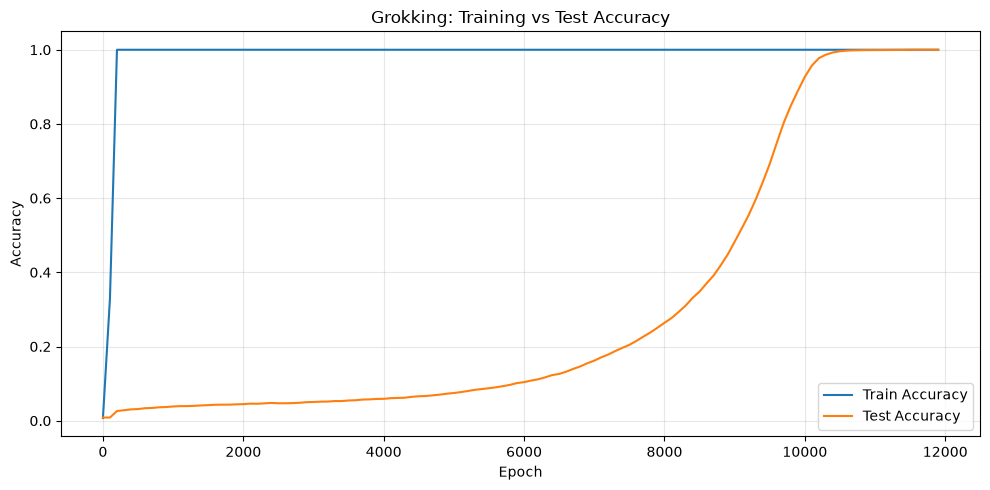

In [23]:
# ============================================================
# Plot Training and Test Accuracy
# ============================================================

import matplotlib.pyplot as plt

epochs = history["epoch"]

plt.figure(figsize=(10, 5))

plt.plot(
    epochs,
    history["train_acc"],
    label="Train Accuracy",
)

plt.plot(
    epochs,
    history["test_acc"],
    label="Test Accuracy",
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Grokking: Training vs Test Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(
    "figures/grokking_accuracy.png",
    dpi=150,
)

plt.show()

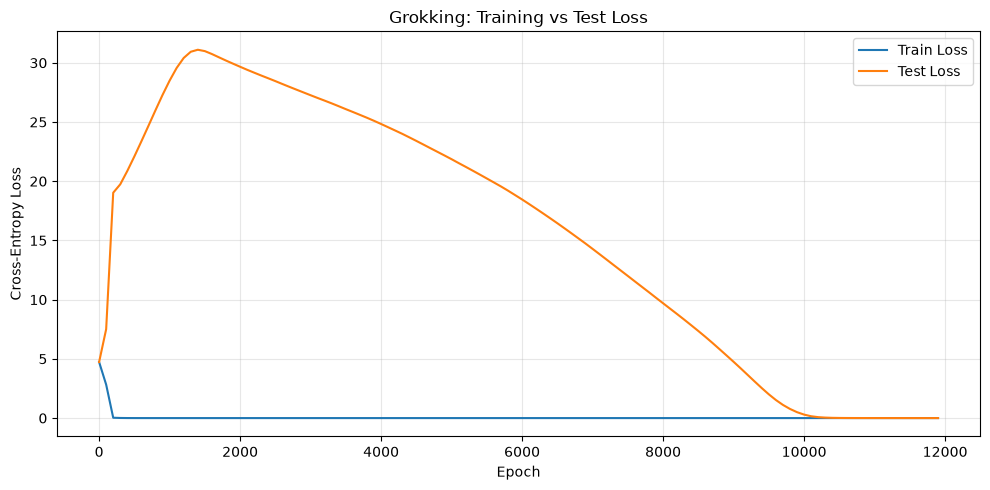

In [24]:
# ============================================================
#  Plot Training and Test Loss
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    epochs,
    history["train_loss"],
    label="Train Loss",
)

plt.plot(
    epochs,
    history["test_loss"],
    label="Test Loss",
)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Grokking: Training vs Test Loss")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(
    "figures/grokking_loss.png",
    dpi=150,
)

plt.show()

**Observation.** Training accuracy is already 1.000 at epoch 200 (train loss 0.030), while test accuracy is only 0.026. Test accuracy first exceeds 90% at epoch 10,000. This long delay between fitting the training set and generalising is the grokking phenomenon.

### Extra view: log-scale loss and weight norm
Test loss is above 28 around epoch 1000, so on a linear axis the later structure is hard to see. A log scale shows it more clearly. We also plot the total parameter norm, which was logged during training; weight decay acts on exactly this quantity.

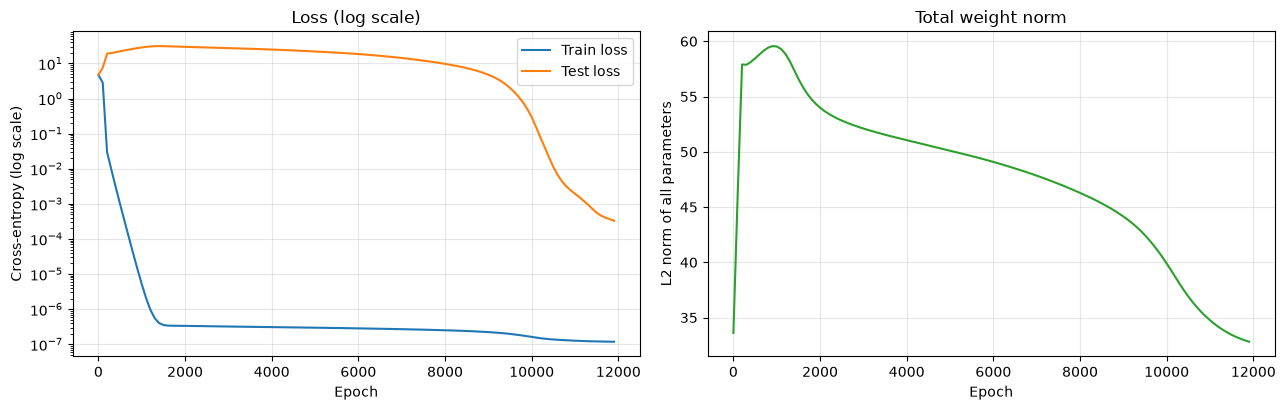

In [25]:
# Re-load history if the kernel was restarted
try:
    history
except NameError:
    history = torch.load("results/training_history.pt")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))

ax[0].plot(history["epoch"], history["train_loss"], label="Train loss")
ax[0].plot(history["epoch"], history["test_loss"], label="Test loss")
ax[0].set_yscale("log")
ax[0].set(xlabel="Epoch", ylabel="Cross-entropy (log scale)", title="Loss (log scale)")
ax[0].legend(); ax[0].grid(True, alpha=0.3)

ax[1].plot(history["epoch"], history["weight_norm"], color="tab:green")
ax[1].set(xlabel="Epoch", ylabel="L2 norm of all parameters", title="Total weight norm")
ax[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("figures/grokking_loss_log_and_weight_norm.png", dpi=150)
plt.show()

## 7. Fourier analysis of the learned embeddings
**Hypothesis (Nanda et al., 2023).** A network that solves modular addition can use the trigonometric identities
$$\cos(\omega(a+b)) = \cos\omega a\,\cos\omega b - \sin\omega a\,\sin\omega b,\qquad \omega = \tfrac{2\pi k}{p},$$
which requires the token embedding to be built from a few sinusoids of key frequencies $k$.

**Test.** Take the DFT of the embedding matrix $W_E[:p]$ along the token axis and measure the L2 norm of each frequency across the embedding dimensions. The DC component is removed, and conjugate frequencies $k$ and $p-k$ are folded together. Frequencies more than 2 standard deviations above the mean are called **key frequencies**.

In [26]:
#  Embedding matrix in Fourier space

W_E = model.W_E[:p].detach().cpu().clone()

print("Embedding matrix shape:", W_E.shape)

Embedding matrix shape: torch.Size([113, 128])


In [27]:
def fourier_norms(W):
    """
    W: [p, d]
    Returns: [p] array containing the L2 norm
    of each DFT frequency across embedding dimensions.
    """

    Fq = np.fft.fft(W.numpy(), axis=0)

    return np.sqrt((np.abs(Fq) ** 2).sum(axis=1))


def folded_spectrum(norms):
    # Keep frequencies 0, 1, ..., p//2
    spec = norms[:p // 2 + 1].copy()

    # Remove the DC (constant) component
    spec[0] = 0.0

    return spec


norms_E = fourier_norms(W_E)
spec_E = folded_spectrum(norms_E)

print("Original Fourier norms shape:", norms_E.shape)
print("Folded spectrum shape:", spec_E.shape)

Original Fourier norms shape: (113,)
Folded spectrum shape: (57,)


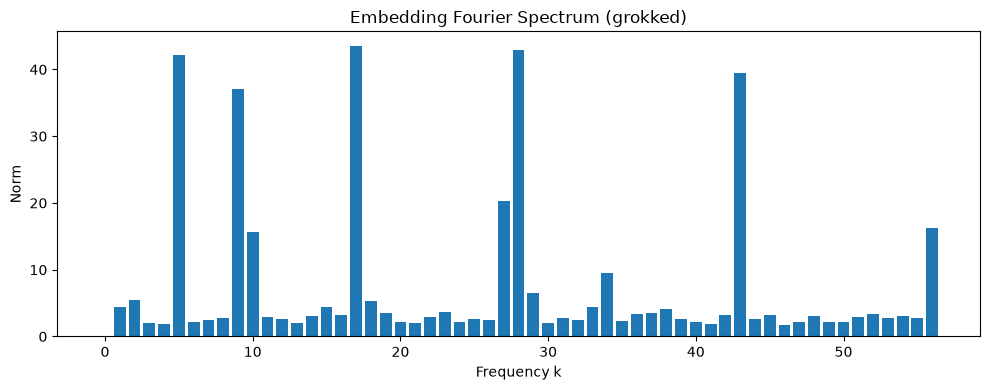

In [28]:
plt.figure(figsize=(10, 4))

plt.bar(range(len(spec_E)), spec_E)

plt.xlabel("Frequency k")
plt.ylabel("Norm")
plt.title("Embedding Fourier Spectrum (grokked)")

plt.tight_layout()
plt.savefig("figures/embedding_fourier.png", dpi=150)
plt.show()

In [29]:
# Step 18: Identify the key frequencies

thr = spec_E[1:].mean() + 2 * spec_E[1:].std()

key_freqs = [
    k
    for k in range(1, p // 2 + 1)
    if spec_E[k] > thr
]

print("Threshold:", thr)
print("Key frequencies:", key_freqs)

Threshold: 29.580313
Key frequencies: [5, 9, 17, 28, 43]


## 8. MLP neurons and attention
We run the model on the full $113 \times 113$ grid and cache the MLP activations at the `=` position. For the four highest-variance neurons we plot activation over $(a, b)$ and against $(a+b) \bmod p$. Periodic structure in the heatmaps is expected if neurons compute products of sinusoids.

We also check where the `=` token attends. All four heads put about **0.50 of their attention on `a`, about 0.50 on `b`, and only 0.002 on `=` itself**, so the heads simply gather the two operands into the final position.

In [30]:
# Step 20 - Create full grid + collect MLP activations + select neurons

# Full input grid
all_a = torch.arange(p, device=device).repeat_interleave(p)
all_b = torch.arange(p, device=device).repeat(p)

all_x = torch.stack(
    [
        all_a,
        all_b,
        torch.full((p * p,), p, device=device)   # '=' token id = p
    ],
    dim=1
)

print("all_x shape:", all_x.shape)


# Collect activations
model.eval()

with torch.no_grad():
    _, cache = model.run_with_cache(all_x)

acts = cache["blocks.0.mlp.hook_post"][:, -1, :].cpu()

acts_grid = acts.reshape(p, p, -1)

print("Activations shape:", acts.shape)
print("Activation grid shape:", acts_grid.shape)


# Select top 4 neurons
top_neurons = acts.var(dim=0).topk(4).indices.tolist()

print("Top 4 neurons:", top_neurons)

all_x shape: torch.Size([12769, 3])
Activations shape: torch.Size([12769, 512])
Activation grid shape: torch.Size([113, 113, 512])
Top 4 neurons: [210, 324, 350, 502]


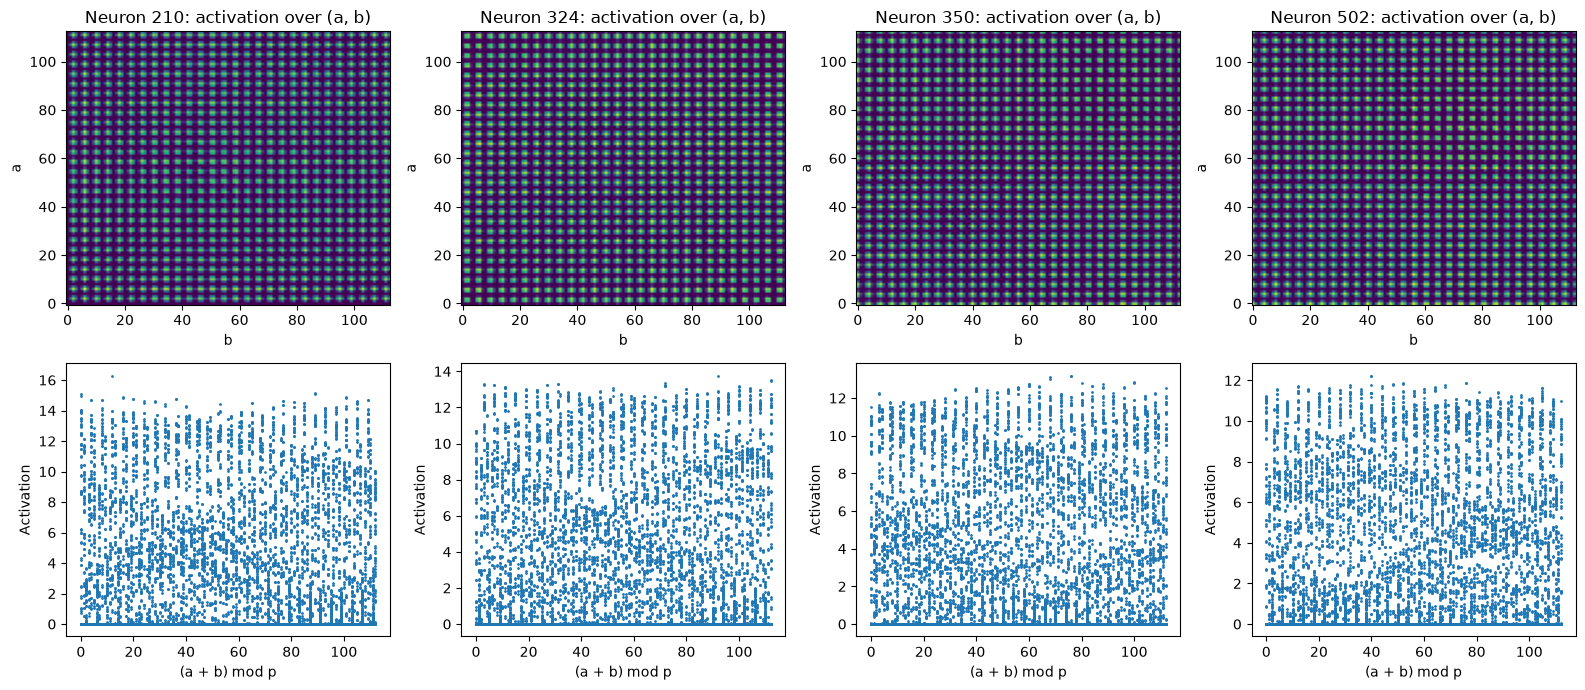

In [31]:
# Step 20: Visualize the top 4 neurons

a_plus_b = (
    (all_x[:, 0] + all_x[:, 1]) % p
).cpu().numpy()

fig, ax = plt.subplots(2, 4, figsize=(16, 7))

for j, n in enumerate(top_neurons):

    # Heatmap
    ax[0, j].imshow(
        acts_grid[:, :, n].numpy(),
        origin="lower",
        aspect="auto"
    )

    ax[0, j].set(
        title=f"Neuron {n}: activation over (a, b)",
        xlabel="b",
        ylabel="a"
    )

    # Activation vs modular sum
    ax[1, j].scatter(
        a_plus_b,
        acts[:, n].numpy(),
        s=1
    )

    ax[1, j].set(
        xlabel="(a + b) mod p",
        ylabel="Activation"
    )

plt.tight_layout()

plt.savefig(
    "figures/neurons.png",
    dpi=150
)

plt.show()

In [32]:
# Step 20b: Attention from the "=" query

attn = cache["blocks.0.attn.hook_pattern"][:, :, -1, :]

print("Attention shape:", attn.shape)

Attention shape: torch.Size([12769, 4, 3])


In [33]:
mean_attn = attn.mean(0).cpu().numpy()

print("Mean attention from '=' to [a, b, =] per head:\n")
print(mean_attn.round(3))

Mean attention from '=' to [a, b, =] per head:

[[0.5   0.498 0.002]
 [0.503 0.495 0.002]
 [0.497 0.501 0.002]
 [0.496 0.502 0.002]]


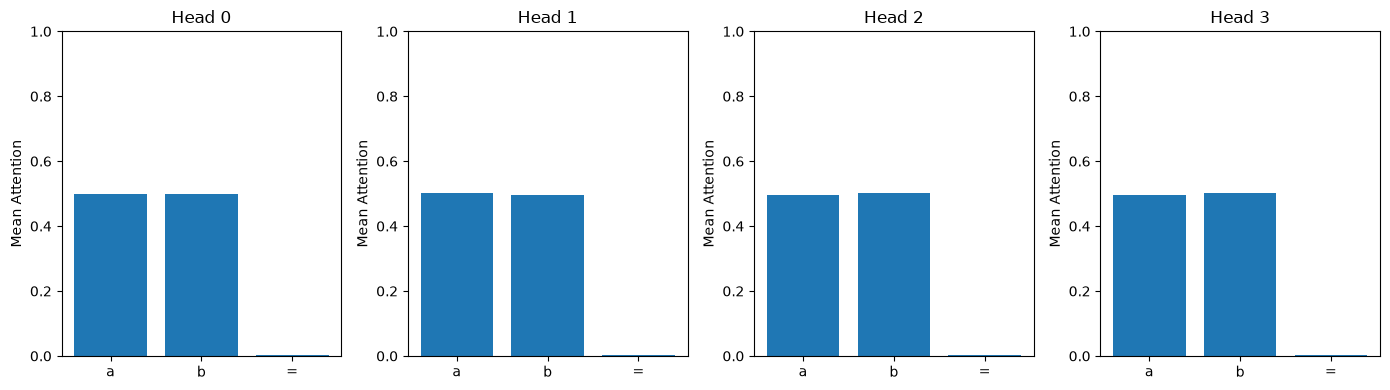

In [34]:
# Visualize mean attention per head

fig, axes = plt.subplots(1, 4, figsize=(14, 4))

positions = ["a", "b", "="]

for h in range(4):
    axes[h].bar(
        positions,
        mean_attn[h]
    )

    axes[h].set_title(f"Head {h}")
    axes[h].set_ylabel("Mean Attention")
    axes[h].set_ylim(0, 1)

plt.tight_layout()
plt.show()

## 9. Unembedding spectrum
If the model reads out the answer in the same Fourier basis, the unembedding $W_U$ should be sparse in the same frequencies. The detected key frequencies match the embedding exactly (overlap 5/5).

In [35]:
# Step 21: Unembedding Fourier spectrum

W_U = model.W_U.detach().cpu().clone()

print("Unembedding shape:", W_U.shape)

Unembedding shape: torch.Size([128, 113])


In [36]:
norms_U = fourier_norms(W_U.T)

spec_U = folded_spectrum(norms_U)

print("Unembedding spectrum shape:", spec_U.shape)

Unembedding spectrum shape: (57,)


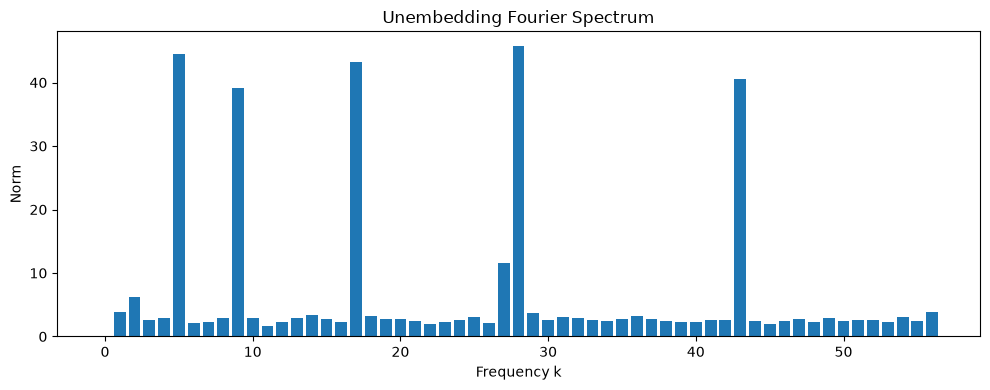

In [37]:
plt.figure(figsize=(10, 4))

plt.bar(
    range(len(spec_U)),
    spec_U
)

plt.xlabel("Frequency k")
plt.ylabel("Norm")
plt.title("Unembedding Fourier Spectrum")

plt.tight_layout()

plt.savefig(
    "figures/unembedding_fourier.png",
    dpi=150
)

plt.show()

In [38]:
key_freqs_U = [
    k
    for k in range(1, p // 2 + 1)
    if spec_U[k] >
       spec_U[1:].mean() + 2 * spec_U[1:].std()
]

print("Embedding key frequencies:", key_freqs)
print("Unembedding key frequencies:", key_freqs_U)

print(
    "Overlap:",
    sorted(set(key_freqs) & set(key_freqs_U))
)

Embedding key frequencies: [5, 9, 17, 28, 43]
Unembedding key frequencies: [5, 9, 17, 28, 43]
Overlap: [5, 9, 17, 28, 43]


## 10. Causal test: Fourier ablation of the output logits
Correlation (a sparse spectrum) is not enough, so we intervene. For each example we take the logits over the 113 answer tokens, apply a DFT along the answer axis, and either

- **keep only** the key frequencies (and their conjugates), or
- **remove** them (keep only the non-key frequencies).

| | Full | Key only | Key removed |
|---|---|---|---|
| Train acc | 1.000 | 1.000 | 0.006 |
| Test acc | 1.000 | 1.000 | 0.003 |

The 5 key frequencies carry essentially all of the useful signal in the logits.

In [39]:
# Step 22: Fourier ablation

def fourier_filter_logits(final_logits, keep_freqs):
    """
    Keep only the specified Fourier frequencies
    and their conjugates along the answer-token axis.

    The DC component (frequency 0) is removed.
    """

    # Convert logits to Fourier space
    Fq = torch.fft.fft(
        final_logits.double(),
        dim=1
    )

    # Create frequency mask
    mask = torch.zeros(
        p,
        dtype=torch.bool,
        device=final_logits.device
    )

    # Keep each requested frequency
    for f in keep_freqs:
        mask[f] = True
        mask[(-f) % p] = True

    # Filter and transform back
    filtered_logits = torch.fft.ifft(
        Fq * mask.to(Fq.dtype),
        dim=1
    ).real

    return filtered_logits

In [40]:
non_key_freqs = [
    f
    for f in range(1, p // 2 + 1)
    if f not in key_freqs
]

print("Key frequencies:", key_freqs)
print("Non-key frequencies:", non_key_freqs)

Key frequencies: [5, 9, 17, 28, 43]
Non-key frequencies: [1, 2, 3, 4, 6, 7, 8, 10, 11, 12, 13, 14, 15, 16, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56]


**Helper functions for ablations.** `ce` and `acc` act on logits that are *already* sliced to the final position (shape `[batch, p]`). They are different from `cross_entropy_loss` / `accuracy_fn` defined earlier, which take the full `[batch, 3, p]` logits and slice internally.

In [41]:
def ce(final_logits, targets):
    """Cross-entropy on already-sliced [batch, p] logits (float64 for precision)."""
    log_probs = final_logits.double().log_softmax(dim=-1)
    return -log_probs.gather(1, targets[:, None]).mean()

def acc(final_logits, targets):
    """Accuracy on already-sliced [batch, p] logits."""
    return (final_logits.argmax(dim=-1) == targets).float().mean().item()


In [42]:
model.eval()

with torch.no_grad():

    for name, x, y in [
        ("train", train_x, train_y),
        ("test", test_x, test_y)
    ]:

        # Original logits
        full = model(x)[:, -1, :]

        # Keep ONLY key frequencies
        restricted = fourier_filter_logits(
            full,
            key_freqs
        )

        # Remove key frequencies
        excluded = fourier_filter_logits(
            full,
            non_key_freqs
        )

        print(f"\n{name.upper()}")

        print(
            f"Full       | "
            f"loss = {ce(full, y):.4f} | "
            f"acc = {acc(full, y):.3f}"
        )

        print(
            f"Key only   | "
            f"loss = {ce(restricted, y):.4f} | "
            f"acc = {acc(restricted, y):.3f}"
        )

        print(
            f"Key removed| "
            f"loss = {ce(excluded, y):.4f} | "
            f"acc = {acc(excluded, y):.3f}"
        )


TRAIN
Full       | loss = 0.0000 | acc = 1.000
Key only   | loss = 0.0000 | acc = 1.000
Key removed| loss = 5.4017 | acc = 0.006

TEST
Full       | loss = 0.0003 | acc = 1.000
Key only   | loss = 0.0001 | acc = 1.000
Key removed| loss = 5.6783 | acc = 0.003


## 11. Causal test: Fourier projection of the embedding
A second, independent intervention. We replace $W_E[:p]$ by a version that contains only the selected frequencies (plus the DC term) and measure test accuracy. The original embedding is always restored afterwards (`try/finally`).

- Key frequencies only → test acc **0.997**
- Non-key frequencies only → test acc **0.016** (≈ chance, 1/113 ≈ 0.009)

In [43]:
# Step 23: Project embedding onto selected Fourier frequencies

def project_embedding(W, freqs_to_keep, keep_dc=True):
    """
    Keep only selected Fourier frequencies in the embedding matrix.
    """

    # Convert embedding matrix to NumPy
    Fq = np.fft.fft(
        W.numpy(),
        axis=0
    )

    # Frequency mask
    mask = np.zeros(
        p,
        dtype=bool
    )

    # Optionally keep the DC component
    if keep_dc:
        mask[0] = True

    # Keep selected frequencies + conjugates
    for f in freqs_to_keep:
        mask[f] = True
        mask[(-f) % p] = True

    # Remove all other frequencies
    filtered = np.real(
        np.fft.ifft(
            Fq * mask[:, None],
            axis=0
        )
    )

    return torch.tensor(
        filtered,
        dtype=torch.float32
    )

In [44]:
# Evaluate model with modified embeddings

def eval_with_embedding(W_new):
    backup = model.W_E.data.clone()

    try:
        model.W_E.data[:p] = W_new.to(device)

        with torch.no_grad():
           logits = model(test_x)

        return acc(logits[:, -1, :], test_y)

    finally:
        # ALWAYS restore original embedding
        model.W_E.data.copy_(backup)

In [45]:
key_only_embedding = project_embedding(
    W_E,
    key_freqs
)

key_only_acc = eval_with_embedding(
    key_only_embedding
)

print(
    "Keep only key frequencies:",
    key_only_acc
)

Keep only key frequencies: 0.9965320229530334


In [46]:
non_key_embedding = project_embedding(
    W_E,
    non_key_freqs
)

non_key_acc = eval_with_embedding(
    non_key_embedding
)

print(
    "Keep only NON-key frequencies:",
    non_key_acc
)

Keep only NON-key frequencies: 0.01610918529331684


**Locating the memorising checkpoint.** We take the earliest saved checkpoint where the model has already fit the training set (train accuracy ≥ 99%) but has not generalised (test accuracy < 10%). We also record the *grokking epoch*, the first logged epoch with test accuracy > 90%.

## 12. Memorising vs. grokked solution
To see *when* the Fourier structure forms, we reload the **memorising checkpoint** (epoch 500: train acc ≥ 99%, test acc < 10%) and compute the same embedding spectrum. We then measure the fraction of non-DC embedding energy that sits in the key frequencies found in the final model:

| | Fraction of energy in key frequencies |
|---|---|
| Memorising checkpoint | 0.141 |
| Grokked model | 0.851 |

For reference, a random embedding would put about $5/56 \approx 0.09$ of its energy in 5 frequency pairs.

In [47]:
idx = lambda e: e // LOG_EVERY
mem_epoch = next(
    e for e in sorted(saved_checkpoints)
    if history["train_acc"][idx(e)] >= 0.99 and history["test_acc"][idx(e)] < 0.1
)
grok_epoch = next(
    (e for e, a in zip(history["epoch"], history["test_acc"]) if a > 0.9),
    None,
)
print("Memorizing checkpoint epoch:", mem_epoch)
print("Test acc first > 90% at epoch:", grok_epoch)


Memorizing checkpoint epoch: 500
Test acc first > 90% at epoch: 10000


In [48]:
# Step 24: Check available checkpoints

print("Memorizing epoch:", mem_epoch)
print("Saved checkpoints:", sorted(saved_checkpoints.keys()))

Memorizing epoch: 500
Saved checkpoints: [0, 500, 1000, 1500, 2000, 2500, 3000, 3500, 4000, 4500, 5000, 5500, 6000, 6500, 7000, 7500, 8000, 8500, 9000, 9500, 10000, 10500, 11000, 11500]


In [49]:
# Load the memorizing checkpoint

ckpts = torch.load(
    "checkpoints/all_checkpoints.pt",
    map_location=device
)

mem_model = HookedTransformer(cfg)

mem_model.load_state_dict(
    ckpts[mem_epoch]
)

mem_model.eval()

print("Loaded memorizing checkpoint:", mem_epoch)

Loaded memorizing checkpoint: 500


C:\Users\jenil\AppData\Local\Temp\ipykernel_12340\3345991641.py:8: DeprecationWarning: HookedTransformer is deprecated and will be removed in 4.0. Use TransformerBridge.boot_transformers(...) instead, then call enable_compatibility_mode() for HookedTransformer-equivalent numerics.
  mem_model = HookedTransformer(cfg)


In [50]:
# Extract embedding from memorizing checkpoint

W_E_mem = (
    mem_model.W_E[:p]
    .detach()
    .cpu()
    .clone()
)

print("Memorizing embedding shape:", W_E_mem.shape)

Memorizing embedding shape: torch.Size([113, 128])


In [51]:
# Fourier spectrum of memorizing checkpoint

norms_mem = fourier_norms(W_E_mem)

spec_mem = folded_spectrum(norms_mem)

print("Memorizing spectrum shape:", spec_mem.shape)

Memorizing spectrum shape: (57,)


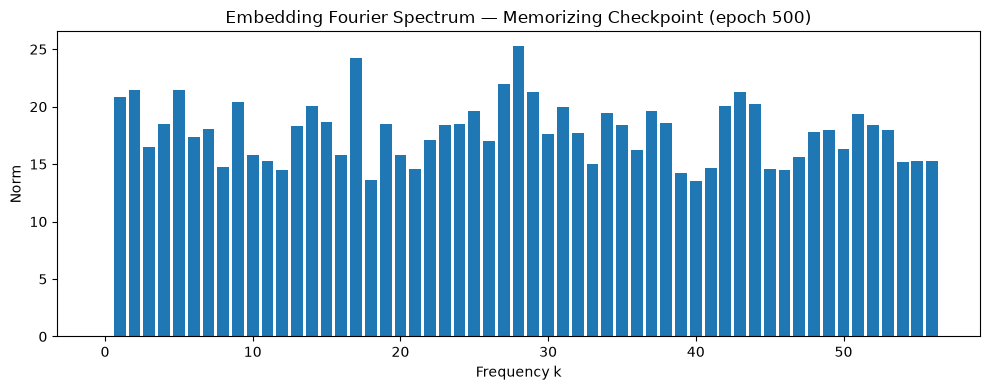

In [52]:
plt.figure(figsize=(10, 4))

plt.bar(
    range(p // 2 + 1),
    spec_mem
)

plt.xlabel("Frequency k")
plt.ylabel("Norm")

plt.title(
    f"Embedding Fourier Spectrum — "
    f"Memorizing Checkpoint (epoch {mem_epoch})"
)

plt.tight_layout()

plt.savefig(
    "figures/embedding_fourier_memorizing.png",
    dpi=150
)

plt.show()

In [53]:
def key_energy_fraction(norms):
    """
    Fraction of non-DC Fourier energy
    contained in the selected key frequencies.
    """

    e = norms ** 2

    # Remove DC energy
    e[0] = 0

    key_energy = sum(
        e[f] + e[p - f]
        for f in key_freqs
    )

    total_energy = e.sum()

    return key_energy / total_energy

In [54]:
mem_fraction = key_energy_fraction(
    norms_mem
)

grokked_fraction = key_energy_fraction(
    norms_E
)

print(
    "Fraction of embedding Fourier energy in key frequencies:"
)

print(
    "Memorizing:",
    round(float(mem_fraction), 3)
)

print(
    "Grokked:",
    round(float(grokked_fraction), 3)
)

Fraction of embedding Fourier energy in key frequencies:
Memorizing: 0.141
Grokked: 0.851


## 13. Progress measure over training
The same energy fraction is computed for every saved checkpoint (every 500 epochs) and plotted against test accuracy. This turns grokking into a continuous progress measure: the internal structure develops over training, while test accuracy looks like a sudden jump.

In [55]:
epochs_s = sorted(saved_checkpoints)

frac = []

for e in epochs_s:
    m = HookedTransformer(cfg)
    m.load_state_dict(saved_checkpoints[e])

    W_E_epoch = m.W_E[:p].detach().cpu().clone()
    norms_epoch = fourier_norms(W_E_epoch)

    frac.append(float(key_energy_fraction(norms_epoch)))

    del m

print("Number of checkpoints:", len(epochs_s))

C:\Users\jenil\AppData\Local\Temp\ipykernel_12340\769598810.py:6: DeprecationWarning: HookedTransformer is deprecated and will be removed in 4.0. Use TransformerBridge.boot_transformers(...) instead, then call enable_compatibility_mode() for HookedTransformer-equivalent numerics.
  m = HookedTransformer(cfg)


Number of checkpoints: 24


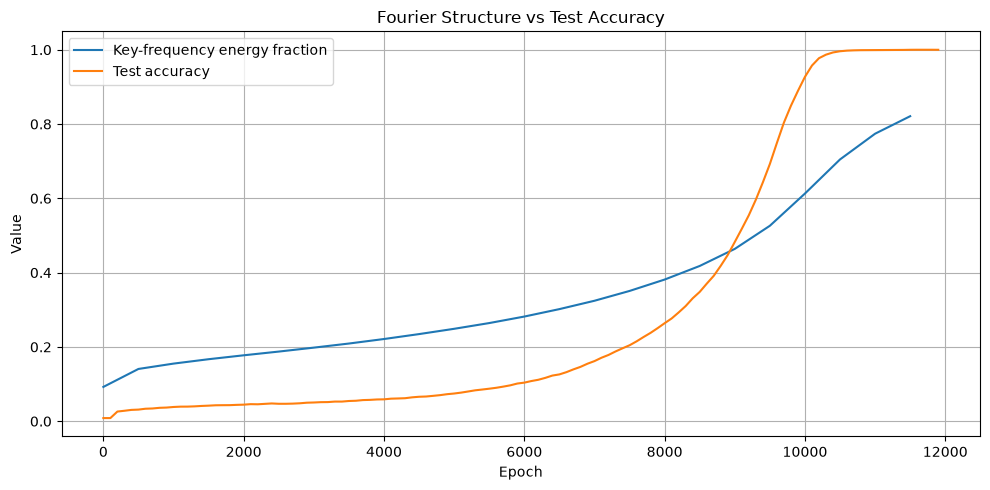

In [56]:
plt.figure(figsize=(10, 5))

plt.plot(
    epochs_s,
    frac,
    label="Key-frequency energy fraction"
)

plt.plot(
    history["epoch"],
    history["test_acc"],
    label="Test accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Value")
plt.title("Fourier Structure vs Test Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig("figures/fourier_vs_accuracy.png", dpi=200)
plt.show()

## 14. Final results

In [57]:
print("=" * 60)
print("FINAL MODEL RESULTS")
print("=" * 60)

print(f"Final Train Accuracy : {history['train_acc'][-1]:.4f}")
print(f"Final Test Accuracy  : {history['test_acc'][-1]:.4f}")

print("\nKey Frequencies:")
print(key_freqs)

print("\nEpoch Information:")
print("First >90% test accuracy:",
      next(
          (e for e, a in zip(history["epoch"], history["test_acc"]) if a > 0.90),
          None
      ))

FINAL MODEL RESULTS
Final Train Accuracy : 1.0000
Final Test Accuracy  : 0.9999

Key Frequencies:
[5, 9, 17, 28, 43]

Epoch Information:
First >90% test accuracy: 10000


In [59]:
print("=" * 60)
print("FOURIER ENERGY")
print("=" * 60)

print("Key frequencies:", key_freqs)

print("Memorization checkpoint:")
print(key_energy_fraction(
    fourier_norms(
        W_E_mem
    )
))

print("\nFinal/Grokked model:")
print(key_energy_fraction(
    fourier_norms(
        model.W_E[:p].detach().cpu().clone()
    )
))

FOURIER ENERGY
Key frequencies: [5, 9, 17, 28, 43]
Memorization checkpoint:
0.14075215

Final/Grokked model:
0.8513025
